In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/H2_clean.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (53042, 36)


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,total_nights,total_guests,has_children,has_company,has_agent
0,0,6,2015,July,27,1,0,2,1,0.0,...,0.0,0,0,Check-Out,2015-07-03,2,1.0,0,0,1
1,1,88,2015,July,27,1,0,4,2,0.0,...,76.5,0,1,Canceled,2015-07-01,4,2.0,0,0,1
2,1,65,2015,July,27,1,0,4,1,0.0,...,68.0,0,1,Canceled,2015-04-30,4,1.0,0,0,1
3,1,92,2015,July,27,1,2,4,2,0.0,...,76.5,0,2,Canceled,2015-06-23,6,2.0,0,0,1
4,1,100,2015,July,27,2,0,2,2,0.0,...,76.5,0,1,Canceled,2015-04-02,2,2.0,0,0,1


In [7]:
print("Number of columns:", df.shape[1])

print("\nAll columns:")
for col in df.columns:
    print(col)

print("\nTarget distribution:")
print(df["IsCanceled"].value_counts())

print("\nTarget percentage:")
print(
    df["IsCanceled"].value_counts(normalize=True) * 100
)

Number of columns: 36

All columns:
IsCanceled
LeadTime
ArrivalDateYear
ArrivalDateMonth
ArrivalDateWeekNumber
ArrivalDateDayOfMonth
StaysInWeekendNights
StaysInWeekNights
Adults
Children
Babies
Meal
Country
MarketSegment
DistributionChannel
IsRepeatedGuest
PreviousCancellations
PreviousBookingsNotCanceled
ReservedRoomType
AssignedRoomType
BookingChanges
DepositType
Agent
Company
DaysInWaitingList
CustomerType
ADR
RequiredCarParkingSpaces
TotalOfSpecialRequests
ReservationStatus
ReservationStatusDate
total_nights
total_guests
has_children
has_company
has_agent

Target distribution:
IsCanceled
0    37021
1    16021
Name: count, dtype: int64

Target percentage:
IsCanceled
0    69.795634
1    30.204366
Name: proportion, dtype: float64


In [8]:
target = "IsCanceled"

leakage_features = [
    "ReservationStatus",
    "ReservationStatusDate",
    "AssignedRoomType",
    "BookingChanges",
    "DaysInWaitingList"
]

investigate_features = [
    "ADR",
    "Agent",
    "Company",
    "has_agent",
    "has_company"
]

def feature_decision(col):
    if col == target:
        return "Target"
    elif col in leakage_features:
        return "Drop - Leakage Risk"
    elif col in investigate_features:
        return "Investigate"
    else:
        return "Keep - Preliminary"

feature_audit = pd.DataFrame({
    "Feature": df.columns,
    "Decision": [
        feature_decision(col)
        for col in df.columns
    ]
})

display(feature_audit.to_string(index=False))

'                    Feature            Decision\n                 IsCanceled              Target\n                   LeadTime  Keep - Preliminary\n            ArrivalDateYear  Keep - Preliminary\n           ArrivalDateMonth  Keep - Preliminary\n      ArrivalDateWeekNumber  Keep - Preliminary\n      ArrivalDateDayOfMonth  Keep - Preliminary\n       StaysInWeekendNights  Keep - Preliminary\n          StaysInWeekNights  Keep - Preliminary\n                     Adults  Keep - Preliminary\n                   Children  Keep - Preliminary\n                     Babies  Keep - Preliminary\n                       Meal  Keep - Preliminary\n                    Country  Keep - Preliminary\n              MarketSegment  Keep - Preliminary\n        DistributionChannel  Keep - Preliminary\n            IsRepeatedGuest  Keep - Preliminary\n      PreviousCancellations  Keep - Preliminary\nPreviousBookingsNotCanceled  Keep - Preliminary\n           ReservedRoomType  Keep - Preliminary\n           Assigned

In [9]:
missing_report = pd.DataFrame({
    "Feature": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_Percent": (
        df.isna().mean().values * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percent",
    ascending=False
)

display(missing_report)

,Feature,Missing_Count,Missing_Percent
23,Company,50300,94.83
22,Agent,5471,10.31
12,Country,3,0.01
9,Children,4,0.01
14,DistributionChannel,4,0.01
2,ArrivalDateYear,0,0.00
1,LeadTime,0,0.00
0,IsCanceled,0,0.00
3,ArrivalDateMonth,0,0.00
8,Adults,0,0.00


In [10]:
cardinality_report = pd.DataFrame({
    "Feature": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Values": df.nunique(dropna=True).values,
    "Unique_Percent": (
        df.nunique(dropna=True).values / len(df) * 100
    ).round(2)
})

cardinality_report = cardinality_report.sort_values(
    by="Unique_Values",
    ascending=False
)

display(cardinality_report)

,Feature,Data_Type,Unique_Values,Unique_Percent
26,ADR,float64,5390,10.16
30,ReservationStatusDate,str,864,1.63
1,LeadTime,int64,453,0.85
22,Agent,float64,223,0.42
23,Company,float64,203,0.38
12,Country,str,166,0.31
24,DaysInWaitingList,int64,114,0.21
17,PreviousBookingsNotCanceled,int64,73,0.14
4,ArrivalDateWeekNumber,int64,53,0.10
31,total_nights,int64,33,0.06


In [11]:
# Numeric features only
numeric_df = df.select_dtypes(include=np.number)

# Exclude target and known leakage features
numeric_df = numeric_df.drop(
    columns=[target] + leakage_features,
    errors="ignore"
)

variance_report = pd.DataFrame({
    "Feature": numeric_df.columns,
    "Variance": numeric_df.var().values,
    "Unique_Values": numeric_df.nunique().values
})

variance_report = variance_report.sort_values(
    by="Variance",
    ascending=True
)

display(variance_report)

,Feature,Variance,Unique_Values
8,Babies,0.010561,5
9,IsRepeatedGuest,0.028227,2
15,RequiredCarParkingSpaces,0.034790,4
20,has_company,0.049023,2
19,has_children,0.088729,2
21,has_agent,0.092508,2
10,PreviousCancellations,0.139737,10
7,Children,0.196508,4
6,Adults,0.286747,5
1,ArrivalDateYear,0.434394,3


In [12]:
from sklearn.preprocessing import MinMaxScaler

# Exclude IDs and features already marked for investigation
exclude_cols = [
    "IsCanceled",
    "Agent",
    "Company"
] + leakage_features

numeric_cols = df.select_dtypes(
    include=np.number
).columns.drop(exclude_cols, errors="ignore")

numeric_data = df[numeric_cols].copy()

# Temporary median filling for exploratory analysis only
numeric_data = numeric_data.fillna(
    numeric_data.median()
)

scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(numeric_data)

minmax_variance_report = pd.DataFrame({
    "Feature": numeric_cols,
    "MinMax_Variance": scaled_data.var(axis=0)
})

minmax_variance_report = (
    minmax_variance_report.sort_values(
        by="MinMax_Variance",
        ascending=True
    )
)

display(minmax_variance_report)

,Feature,MinMax_Variance
8,Babies,0.000106
10,PreviousCancellations,0.000317
11,PreviousBookingsNotCanceled,0.000807
15,total_nights,0.001876
5,StaysInWeekNights,0.002172
13,RequiredCarParkingSpaces,0.003865
16,total_guests,0.004006
4,StaysInWeekendNights,0.004178
12,ADR,0.006588
0,LeadTime,0.017051


In [13]:
df_classification = df.drop(
    columns=leakage_features
).copy()

print("Before:", df.shape)
print("After:", df_classification.shape)

Before: (53042, 36)
After: (53042, 31)


In [14]:
# Keep ADR provisionally as booking-time price
# Exclude uncertain agent/company information

uncertain_features = [
    "Agent",
    "Company",
    "has_agent",
    "has_company"
]

df_classification = df_classification.drop(
    columns=uncertain_features
).copy()

print("Final working shape:", df_classification.shape)

print(
    "Remaining leakage columns:",
    set(leakage_features).intersection(df_classification.columns)
)

print(
    "Target exists:",
    "IsCanceled" in df_classification.columns
)

Final working shape: (53042, 27)
Remaining leakage columns: set()
Target exists: True


In [15]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Select numeric features only (exclude target)
numeric_df = df_classification.select_dtypes(
    include=np.number
).drop(columns=["IsCanceled"], errors="ignore")

# 2. Calculate raw variance
raw_variance = numeric_df.var()

# 3. Temporary missing-value handling for EDA
numeric_filled = numeric_df.fillna(numeric_df.median())

# 4. Calculate MinMax-scaled variance
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(numeric_filled)

minmax_variance = pd.Series(
    scaled_data.var(axis=0),
    index=numeric_df.columns
)

# 5. Create variance report
variance_report = pd.DataFrame({
    "Feature": numeric_df.columns,
    "Raw_Variance": raw_variance.values,
    "MinMax_Variance": minmax_variance.values,
    "Unique_Values": numeric_df.nunique().values
})

variance_report = variance_report.sort_values(
    by="MinMax_Variance",
    ascending=True
)

display(variance_report)

,Feature,Raw_Variance,MinMax_Variance,Unique_Values
8,Babies,0.010561,0.000106,5
10,PreviousCancellations,0.139737,0.000317,10
11,PreviousBookingsNotCanceled,4.183247,0.000807,73
15,total_nights,4.144825,0.001876,33
5,StaysInWeekNights,2.510882,0.002172,26
13,RequiredCarParkingSpaces,0.034790,0.003865,4
16,total_guests,0.484737,0.004006,7
4,StaysInWeekendNights,0.818989,0.004178,12
12,ADR,1713.575371,0.006588,5390
0,LeadTime,6746.385469,0.017051,453


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("\nPreprocessing pipeline is ready!")

Numeric features: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'total_nights', 'total_guests', 'has_children']
Categorical features: ['ArrivalDateMonth', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'ReservedRoomType', 'DepositType', 'CustomerType']

Preprocessing pipeline is ready!


In [19]:
# Step 6.1: Feature Distributions

import pandas as pd
import numpy as np

# Classification features only, excluding target
X_eda = df_classification.drop(
    columns=["IsCanceled"]
)

# Numeric features
numeric_cols = X_eda.select_dtypes(
    include=np.number
).columns

# Categorical features
categorical_cols = X_eda.select_dtypes(
    include=["object", "category", "string"]
).columns

# Numeric distribution summary
numeric_distribution = pd.DataFrame({
    "Feature": numeric_cols,
    "Mean": X_eda[numeric_cols].mean().values,
    "Median": X_eda[numeric_cols].median().values,
    "Std": X_eda[numeric_cols].std().values,
    "Pct_Most_Common": [
        X_eda[col].value_counts(
            normalize=True, dropna=False
        ).iloc[0] * 100
        for col in numeric_cols
    ]
})

# Categorical distribution summary
categorical_distribution = pd.DataFrame({
    "Feature": categorical_cols,
    "Unique_Values": [
        X_eda[col].nunique(dropna=True)
        for col in categorical_cols
    ],
    "Pct_Top": [
        X_eda[col].value_counts(
            normalize=True, dropna=False
        ).iloc[0] * 100
        for col in categorical_cols
    ]
})

print("Numeric Distribution:")
display(numeric_distribution.round(2))

print("Categorical Distribution:")
display(categorical_distribution.round(2))

Numeric Distribution:


,Feature,Mean,Median,Std,Pct_Most_Common
0,LeadTime,78.04,51.00,82.14,5.11
1,ArrivalDateYear,2016.26,2016.00,0.66,50.05
2,ArrivalDateWeekNumber,26.63,27.00,13.57,3.09
3,ArrivalDateDayOfMonth,15.76,16.00,8.80,3.51
4,StaysInWeekendNights,0.87,1.00,0.90,43.23
5,StaysInWeekNights,2.28,2.00,1.58,27.86
6,Adults,1.88,2.00,0.54,71.36
7,Children,0.13,0.00,0.44,90.71
8,Babies,0.01,0.00,0.10,99.31
9,IsRepeatedGuest,0.03,0.00,0.17,97.09


Categorical Distribution:


,Feature,Unique_Values,Pct_Top
0,ArrivalDateMonth,12,12.37
1,Meal,4,77.27
2,Country,166,24.38
3,MarketSegment,7,65.66
4,DistributionChannel,4,83.52
5,ReservedRoomType,7,70.98
6,DepositType,3,98.38
7,CustomerType,4,83.55


In [20]:
# Step 6.1 - Distribution findings

distribution_findings = pd.DataFrame({
    "Feature": [
        "Babies",
        "IsRepeatedGuest",
        "PreviousCancellations",
        "PreviousBookingsNotCanceled",
        "RequiredCarParkingSpaces",
        "DepositType",
        "Country",
        "LeadTime"
    ],
    "Finding": [
        "99.31% same value",
        "97.09% same value",
        "97.79% same value",
        "97.14% same value",
        "96.44% same value",
        "98.38% dominant category",
        "166 unique categories",
        "Mean greater than median"
    ],
    "Decision": ["Investigate"] * 8
})

display(distribution_findings)

,Feature,Finding,Decision
0,Babies,99.31% same value,Investigate
1,IsRepeatedGuest,97.09% same value,Investigate
2,PreviousCancellations,97.79% same value,Investigate
3,PreviousBookingsNotCanceled,97.14% same value,Investigate
4,RequiredCarParkingSpaces,96.44% same value,Investigate
5,DepositType,98.38% dominant category,Investigate
6,Country,166 unique categories,Investigate
7,LeadTime,Mean greater than median,Investigate


In [21]:
# Step 6.2 - Outliers Analysis (IQR)

outlier_cols = [
    "LeadTime",
    "StaysInWeekendNights",
    "StaysInWeekNights",
    "PreviousCancellations",
    "PreviousBookingsNotCanceled",
    "ADR",
    "total_nights",
    "total_guests"
]

outlier_results = []

for col in outlier_cols:
    s = df_classification[col].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_count = ((s < lower) | (s > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": outlier_count,
        "Outlier_Percent": round(
            outlier_count / len(s) * 100, 2
        )
    })

outlier_report = pd.DataFrame(outlier_results)

display(
    outlier_report.sort_values(
        "Outlier_Percent",
        ascending=False
    )
)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percent
7,total_guests,2.00,2.00,19364,36.51
5,ADR,11.35,207.75,2218,4.18
0,LeadTime,-142.00,274.00,1694,3.19
4,PreviousBookingsNotCanceled,0.00,0.00,1516,2.86
3,PreviousCancellations,0.00,0.00,1171,2.21
6,total_nights,-1.00,7.00,1157,2.18
2,StaysInWeekNights,-2.00,6.00,665,1.25
1,StaysInWeekendNights,-3.00,5.00,73,0.14


### Step 6.2 — Outlier Analysis Findings

- **total_guests:** IQR identifies 36.51% as outliers because Q1 = Q3 = 2. This is not sufficient evidence of invalid values.
- **ADR:** 4.18% of values fall outside the IQR bounds. Flag for further investigation.
- **LeadTime:** 3.19% of values fall outside the IQR bounds. Long booking lead times may be legitimate.
- **PreviousCancellations / PreviousBookingsNotCanceled:** IQR flags non-zero values because both quartiles are zero. These values may carry predictive information.
- **Stay duration features:** Some longer stays are flagged, but they are not necessarily invalid.

**Decision:** Retain all observations and features for now. No outlier removal or capping is applied at this stage.

Correlation with IsCanceled:


,Correlation
LeadTime,0.189721
TotalOfSpecialRequests,-0.165866
RequiredCarParkingSpaces,-0.126005
total_nights,0.114600
StaysInWeekNights,0.111581
ADR,0.087209
ArrivalDateYear,0.082308
total_guests,0.081574
Adults,0.081359
IsRepeatedGuest,-0.068127


Strong feature correlations (>= 0.8):


,Feature_1,Feature_2,Abs_Correlation
143,Children,has_children,0.904987
105,StaysInWeekNights,total_nights,0.904633


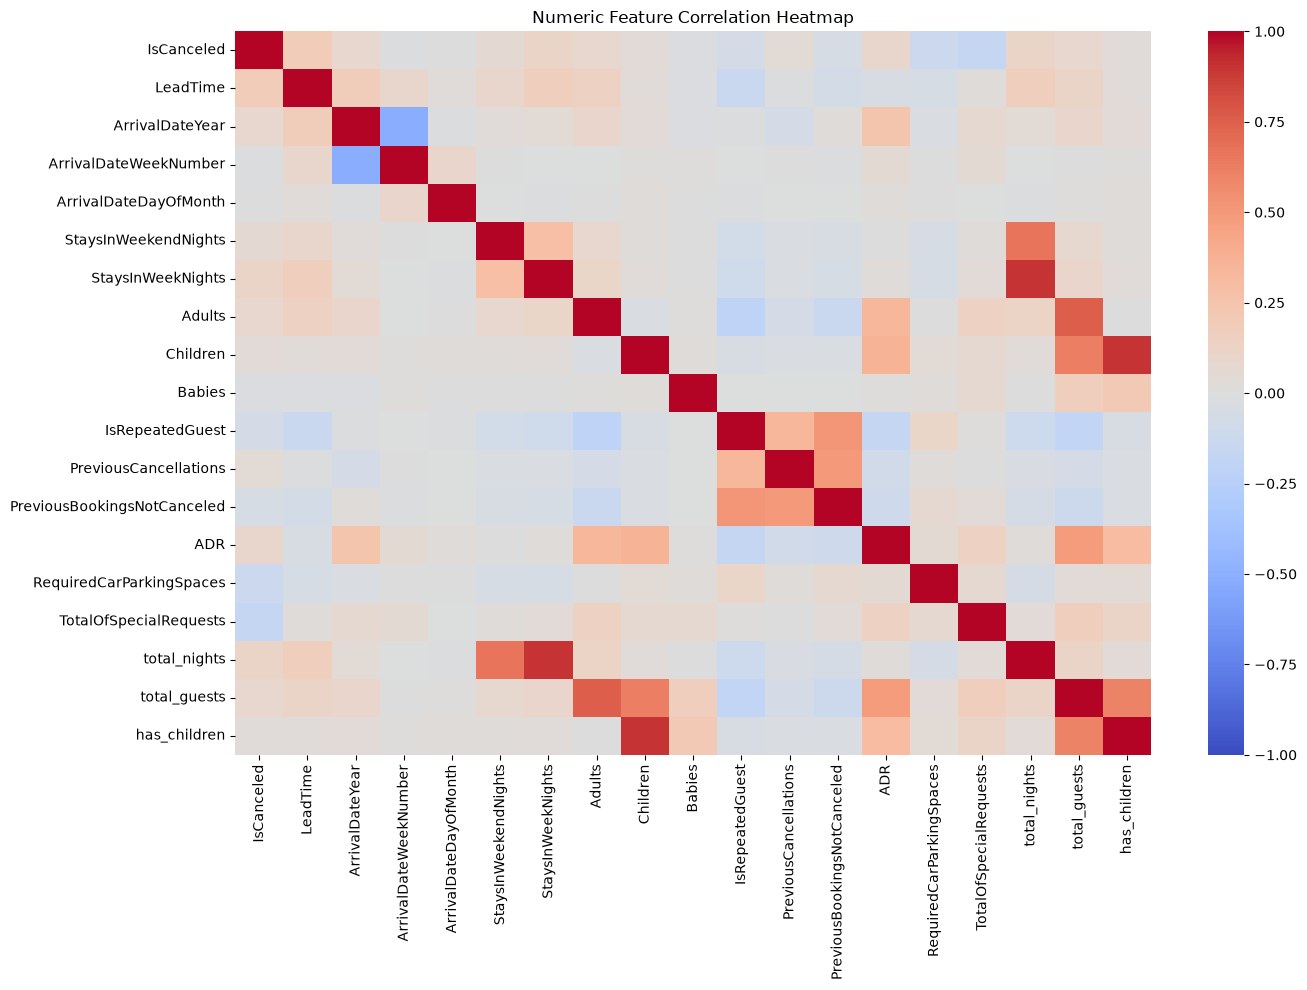

In [22]:
# Step 6.3 - Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df_classification.select_dtypes(
    include="number"
)

corr_matrix = numeric_df.corr(method="pearson")

# 1. Correlation with target
target_corr = (
    corr_matrix["IsCanceled"]
    .drop("IsCanceled")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with IsCanceled:")
display(target_corr.to_frame("Correlation"))

# 2. Strong correlations between features
feature_corr = corr_matrix.drop(
    index="IsCanceled",
    columns="IsCanceled"
).abs()

upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

strong_pairs = (
    upper_triangle.stack()
    .reset_index()
)

strong_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Abs_Correlation"
]

strong_pairs = strong_pairs[
    strong_pairs["Abs_Correlation"] >= 0.8
].sort_values(
    "Abs_Correlation",
    ascending=False
)

print("Strong feature correlations (>= 0.8):")
display(strong_pairs)

# 3. Correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Numeric Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### Step 6.3 — Correlation Analysis Findings

**Target correlations:**
- LeadTime has the strongest positive Pearson correlation with IsCanceled (+0.1897).
- TotalOfSpecialRequests (-0.1659) and RequiredCarParkingSpaces (-0.1260) show the strongest negative correlations.
- Most individual numeric features have weak linear correlations with the target.

**Strong feature correlations:**
- Children and has_children: |r| = 0.905
- StaysInWeekNights and total_nights: |r| = 0.905

**Decision:** Flag these feature pairs for redundancy investigation in Step 7. Do not remove features based on Pearson correlation alone. Retain the current dataset unchanged.

In [23]:
# Step 7 - Preliminary Feature Decisions

target = "IsCanceled"

leakage_features = [
    "ReservationStatus",
    "ReservationStatusDate",
    "AssignedRoomType",
    "BookingChanges",
    "DaysInWaitingList"
]

provisional_exclusions = [
    "Agent",
    "Company",
    "has_agent",
    "has_company"
]

investigate_features = [
    "ADR",
    "Children",
    "has_children",
    "StaysInWeekNights",
    "total_nights",
    "Babies",
    "IsRepeatedGuest",
    "PreviousCancellations",
    "PreviousBookingsNotCanceled",
    "RequiredCarParkingSpaces",
    "Country",
    "DepositType"
]

feature_decisions = []

for col in df.columns:
    if col == target:
        decision = "Target"
        reason = "Prediction target"

    elif col in leakage_features:
        decision = "Remove"
        reason = "Potential post-booking leakage"

    elif col in provisional_exclusions:
        decision = "Investigate - Excluded"
        reason = "Booking-time availability unverified"

    elif col in investigate_features:
        decision = "Investigate - Kept"
        reason = "Requires further review; retained provisionally"

    else:
        decision = "Keep"
        reason = "No sufficient reason for removal"

    feature_decisions.append({
        "Feature": col,
        "Decision": decision,
        "Reason": reason
    })

feature_decisions_df = pd.DataFrame(feature_decisions)

display(feature_decisions_df)

# Apply preliminary exclusions to the original cleaned dataset
columns_to_exclude = leakage_features + provisional_exclusions

df_classification = df.drop(
    columns=columns_to_exclude
).copy()

print("Classification shape:", df_classification.shape)
print("Target present:", target in df_classification.columns)

,Feature,Decision,Reason
0,IsCanceled,Target,Prediction target
1,LeadTime,Keep,No sufficient reason for removal
2,ArrivalDateYear,Keep,No sufficient reason for removal
3,ArrivalDateMonth,Keep,No sufficient reason for removal
4,ArrivalDateWeekNumber,Keep,No sufficient reason for removal
5,ArrivalDateDayOfMonth,Keep,No sufficient reason for removal
6,StaysInWeekendNights,Keep,No sufficient reason for removal
7,StaysInWeekNights,Investigate - Kept,Requires further review; retained provisionally
8,Adults,Keep,No sufficient reason for removal
9,Children,Investigate - Kept,Requires further review; retained provisionally


Classification shape: (53042, 27)
Target present: True


In [24]:
print("Dataset shape:", df_classification.shape)
print("Features:", df_classification.shape[1] - 1)
print("Target:", "IsCanceled" in df_classification.columns)

excluded = leakage_features + provisional_exclusions

print(
    "Excluded columns remaining:",
    set(excluded) & set(df_classification.columns)
)

Dataset shape: (53042, 27)
Features: 26
Target: True
Excluded columns remaining: set()


In [25]:
from sklearn.model_selection import train_test_split

# Step 8 - Train / Validation / Test Split

X = df_classification.drop(columns=["IsCanceled"])
y = df_classification["IsCanceled"]

# 20% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 10% Validation from the full dataset
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.125,
    random_state=42,
    stratify=y_train_val
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (37128, 26) (37128,)
Validation: (5305, 26) (5305,)
Test: (10609, 26) (10609,)


In [26]:
import pandas as pd

split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Rows": [len(y_train), len(y_val), len(y_test)],
    "Percentage": [
        len(y_train) / len(y) * 100,
        len(y_val) / len(y) * 100,
        len(y_test) / len(y) * 100
    ],
    "Cancellation_Rate": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary.round(2))

print("No overlapping indices:",
      set(X_train.index).isdisjoint(X_val.index)
      and set(X_train.index).isdisjoint(X_test.index)
      and set(X_val.index).isdisjoint(X_test.index))

,Dataset,Rows,Percentage,Cancellation_Rate
0,Train,37128,70.0,30.21
1,Validation,5305,10.0,30.20
2,Test,10609,20.0,30.20


No overlapping indices: True


In [27]:
print(
    "No overlapping indices:",
    set(X_train.index).isdisjoint(X_val.index)
    and set(X_train.index).isdisjoint(X_test.index)
    and set(X_val.index).isdisjoint(X_test.index)
)

No overlapping indices: True


In [28]:
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numeric_features) + len(categorical_features))

print("Preprocessor:")
print(preprocessor)

Numeric features: 18
Categorical features: 8
Total features: 26
Preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['LeadTime', 'ArrivalDateYear',
                                  'ArrivalDateWeekNumber',
                                  'ArrivalDateDayOfMonth',
                                  'StaysInWeekendNights', 'StaysInWeekNights',
                                  'Adults', 'Children', 'Babies',
                                  'IsRepeatedGuest', 'PreviousCancellations',
                                  'PreviousBookingsNotCanceled...
                                  'RequiredCarParkingSpaces',
                                  'TotalOfSpecialRequests', 'total_nights',
                                  'total_gues

In [29]:
# Step 10 - VarianceThreshold

from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline

variance_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("variance", VarianceThreshold(threshold=0.0))
])

print(variance_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LeadTime',
                                                   'ArrivalDateYear',
                                                   'ArrivalDateWeekNumber',
                                                   'ArrivalDateDayOfMonth',
                                                   'StaysInWeekendNights',
                                                   'StaysInWeekNights',
                                                   'Adults', 'Children',
                                                   'Babies',

In [30]:
print("Pipeline steps:", list(variance_pipeline.named_steps.keys()))

print(
    "Variance threshold:",
    variance_pipeline.named_steps["variance"].threshold
)

Pipeline steps: ['preprocessor', 'variance']
Variance threshold: 0.0


In [31]:
# Step 10 - Fit VarianceThreshold on training data only

variance_pipeline.fit(X_train)

# Feature names after preprocessing
feature_names = variance_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Features retained by VarianceThreshold
selector = variance_pipeline.named_steps["variance"]
selected_mask = selector.get_support()

kept_features = feature_names[selected_mask]
removed_features = feature_names[~selected_mask]

print("Features before VarianceThreshold:", len(feature_names))
print("Features after VarianceThreshold:", len(kept_features))
print("Removed features:", len(removed_features))

print("\nRemoved feature names:")
print(removed_features)

Features before VarianceThreshold: 212
Features after VarianceThreshold: 212
Removed features: 0

Removed feature names:
[]


### Step 10 — VarianceThreshold Results

- Features after preprocessing: 212
- Features retained: 212
- Features removed: 0
- Threshold: 0.0
- Fitted on training data only.

**Decision:** Retain VarianceThreshold(threshold=0.0) in the pipeline. No constant features were detected. No additional feature removal is justified at this stage.

For future cross-validation experiments, preprocessing and variance filtering must be fitted inside each training fold.

In [42]:
# Step 11.1 - Mutual Information Feature Selection

import numpy as np
import pandas as pd

from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif,
    VarianceThreshold
)
from sklearn.pipeline import Pipeline

# Number of original numeric features
n_numeric = len(numeric_features)

# Numeric features treated as discrete
discrete_numeric = {
    "IsRepeatedGuest",
    "PreviousCancellations",
    "PreviousBookingsNotCanceled",
    "Adults",
    "Children",
    "Babies",
    "RequiredCarParkingSpaces",
    "TotalOfSpecialRequests",
    "has_children"
}

# Mutual Information scoring function
def mi_score_func(X, y):

    discrete_mask = np.zeros(X.shape[1], dtype=bool)

    # Numeric features are treated as continuous
    # One-hot encoded features are treated as discrete
    discrete_mask[n_numeric:] = True

    return mutual_info_classif(
        X,
        y,
        discrete_features=discrete_mask,
        random_state=42
    )


# Select top 50 features
mi_selector = SelectKBest(
    score_func=mi_score_func,
    k=50
)

# Build pipeline
mi_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("mi", mi_selector)
])

# Fit on training data only
mi_pipeline.fit(X_train, y_train)


# Get feature names after preprocessing
encoded_names = mi_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Apply variance selection mask
variance_mask = mi_pipeline.named_steps[
    "variance"
].get_support()

names_after_variance = encoded_names[variance_mask]


# Create MI results table
mi_results = pd.DataFrame({
    "Feature": names_after_variance,
    "MI_Score": mi_pipeline.named_steps["mi"].scores_,
    "Selected": mi_pipeline.named_steps["mi"].get_support()
})

# Sort by MI score
mi_results = mi_results.sort_values(
    "MI_Score",
    ascending=False
)

# Display results
print("Features before MI:", len(names_after_variance))
print("Features selected by MI:", mi_results["Selected"].sum())

display(mi_results.head(20))

Features before MI: 212
Features selected by MI: 50


,Feature,MI_Score,Selected
0,num__LeadTime,0.036185,True
12,num__ADR,0.032722,True
14,num__TotalOfSpecialRequests,0.018941,True
193,cat__MarketSegment_Online TA,0.017276,True
206,cat__DepositType_Non Refund,0.016578,True
205,cat__DepositType_No Deposit,0.016450,True
10,num__PreviousCancellations,0.013953,True
13,num__RequiredCarParkingSpaces,0.013830,True
197,cat__DistributionChannel_TA/TO,0.011576,True
5,num__StaysInWeekNights,0.008371,True


### Step 11.1 — Mutual Information Results

- Features before selection: 212
- Features selected: 50
- Selection method: SelectKBest(mutual_info_classif, k=50)
- Fitted on training data only.
- Highest MI scores: LeadTime (0.0362), ADR (0.0327), TotalOfSpecialRequests (0.0189), MarketSegment_Online TA (0.0173), and DepositType_Non Refund (0.0166).

**Decision:** Keep MI with k=50 as a candidate feature-selection method. Final selection will depend on model performance comparisons in Step 12.

In [38]:
# Step 11.2 - L1 Feature Selection

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel, VarianceThreshold
from sklearn.linear_model import LogisticRegression

l1_selector = SelectFromModel(
    estimator=LogisticRegression(
        l1_ratio=1.0,
        solver="liblinear",
        C=0.1,
        max_iter=2000,
        random_state=42
    ),
    threshold=1e-5
)

l1_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("l1", l1_selector)
])

# Fit on training data only
l1_pipeline.fit(X_train, y_train)

# Feature names after preprocessing and variance filtering
encoded_names = l1_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

variance_mask = l1_pipeline.named_steps[
    "variance"
].get_support()

names_after_variance = encoded_names[variance_mask]

# L1 selected features
l1_mask = l1_pipeline.named_steps[
    "l1"
].get_support()

l1_results = pd.DataFrame({
    "Feature": names_after_variance,
    "Coefficient": l1_pipeline.named_steps[
        "l1"
    ].estimator_.coef_[0],
    "Selected": l1_mask
})

l1_results["Abs_Coefficient"] = (
    l1_results["Coefficient"].abs()
)

l1_results = l1_results.sort_values(
    "Abs_Coefficient",
    ascending=False
)

print("Features before L1:", len(names_after_variance))
print("Features selected by L1:", l1_mask.sum())
print("Features removed by L1:", (~l1_mask).sum())

display(l1_results.head(20))

Features before L1: 212
Features selected by L1: 67
Features removed by L1: 145


,Feature,Coefficient,Selected,Abs_Coefficient
205,cat__DepositType_No Deposit,-2.614746,True,2.614746
13,num__RequiredCarParkingSpaces,-1.185520,True,1.185520
35,cat__Country_AGO,1.131832,True,1.131832
151,cat__Country_PRT,1.125352,True,1.125352
59,cat__Country_CHN,0.981051,True,0.981051
193,cat__MarketSegment_Online TA,0.978038,True,0.978038
79,cat__Country_FIN,-0.694542,True,0.694542
204,cat__ReservedRoomType_G,-0.673402,True,0.673402
206,cat__DepositType_Non Refund,0.647529,True,0.647529
14,num__TotalOfSpecialRequests,-0.639888,True,0.639888


In [43]:
# Step 12 - Compare Feature Selection Methods

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold, SelectKBest, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

base_model = LogisticRegression(
    solver="liblinear",
    max_iter=2000,
    random_state=42
)

selection_methods = {
    "No Selection": "passthrough",

    "Mutual Information": SelectKBest(
        score_func=mi_score_func,
        k=50
    ),

    "L1": SelectFromModel(
        LogisticRegression(
            l1_ratio=1.0,
            solver="liblinear",
            C=0.1,
            max_iter=2000,
            random_state=42
        ),
        threshold=1e-5
    )
}

results = []

for name, selector in selection_methods.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("variance", VarianceThreshold(threshold=0.0)),
        ("selection", selector),
        ("model", clone(base_model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "precision": "precision",
            "recall": "recall",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    results.append({
        "Method": name,
        "F1_Mean": scores["test_f1"].mean(),
        "F1_Std": scores["test_f1"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

comparison_df = pd.DataFrame(results)
display(comparison_df.sort_values("F1_Mean", ascending=False))

,Method,F1_Mean,F1_Std,Precision,Recall,ROC_AUC
0,No Selection,0.539054,0.009156,0.669865,0.451092,0.805113
2,L1,0.535752,0.007582,0.667727,0.447436,0.803670
1,Mutual Information,0.524318,0.008583,0.665766,0.432546,0.799091


In [45]:
# Step 12 - Check feature counts across CV folds

from sklearn.base import clone

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    fold_preprocessor = clone(preprocessor)

    X_fold = X_train.iloc[train_idx]
    y_fold = y_train.iloc[train_idx]

    X_encoded = fold_preprocessor.fit_transform(X_fold, y_fold)

    fold_variance = VarianceThreshold(threshold=0.0)
    X_filtered = fold_variance.fit_transform(X_encoded)

    print(
        f"Fold {fold}: "
        f"{X_encoded.shape[1]} before variance, "
        f"{X_filtered.shape[1]} after variance"
    )

Fold 1: 203 before variance, 203 after variance
Fold 2: 208 before variance, 208 after variance
Fold 3: 208 before variance, 208 after variance
Fold 4: 211 before variance, 211 after variance
Fold 5: 201 before variance, 201 after variance


In [50]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 3.4 MB/s eta 0:00:15
   - -------------------------------------- 1.6/48.9 MB 3.8 MB/s eta 0:00:13
   - -------------------------------------- 2.4/48.9 MB 3.8 MB/s eta 0:00:13
   -- ------------------------------------- 3.1/48.9 MB 3.9 MB/s eta 0:00:12
   --- ------------------------------------ 3.9/48.9 MB 3.9 MB/s eta 0:00:12
   --- ------------------------------------ 4.7/48.9 MB 3.8 MB/s eta 0:00:12
   ---- ----------------------------------- 5.5/48.9 MB 3.7 MB/s eta 0:00:12
   ---- ----------------------------------- 6.0/48.9 MB 3.7 MB/s eta 0:00:12
   ----- ---------------------------------- 6.8/48.9 MB 3.6 MB/s eta 0:00:12
   ----- ---------------------------------- 7.3/48.9 MB 3.6 MB/s eta 0:00:12
   ------ --------------------------------- 8.1/48.9 MB 3.5 MB/s eta 0:00:12
   ------- --


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [53]:
# Step 13 - Baseline Model Comparison

import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

cv_baseline = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_models = {
    "Logistic Regression": LogisticRegression(
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )
}

baseline_results = []

for model_name, model in baseline_models.items():

    print(f"Evaluating: {model_name}")

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("variance", VarianceThreshold(threshold=0.0)),
        ("model", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_baseline,
        scoring={
            "f1": "f1",
            "precision": "precision",
            "recall": "recall",
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=1,
        error_score="raise"
    )

    baseline_results.append({
        "Model": model_name,
        "F1_Mean": scores["test_f1"].mean(),
        "F1_Std": scores["test_f1"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "Accuracy": scores["test_accuracy"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

baseline_df = pd.DataFrame(baseline_results)

display(
    baseline_df.sort_values(
        "F1_Mean",
        ascending=False
    )
)

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: XGBoost


,Model,F1_Mean,F1_Std,Precision,Recall,Accuracy,ROC_AUC
2,XGBoost,0.656619,0.005092,0.723328,0.601248,0.810063,0.871398
1,Random Forest,0.638000,0.005856,0.737202,0.562372,0.807235,0.861704
0,Logistic Regression,0.539054,0.009156,0.669865,0.451092,0.766968,0.805113


In [54]:
print("Number of features:", X_train.shape[1])
print("\nFeatures used:")

for col in X_train.columns:
    print(col)

Number of features: 26

Features used:
LeadTime
ArrivalDateYear
ArrivalDateMonth
ArrivalDateWeekNumber
ArrivalDateDayOfMonth
StaysInWeekendNights
StaysInWeekNights
Adults
Children
Babies
Meal
Country
MarketSegment
DistributionChannel
IsRepeatedGuest
PreviousCancellations
PreviousBookingsNotCanceled
ReservedRoomType
DepositType
CustomerType
ADR
RequiredCarParkingSpaces
TotalOfSpecialRequests
total_nights
total_guests
has_children


In [55]:
suspicious_features = [
    "ReservationStatus",
    "ReservationStatusDate",
    "BookingChanges",
    "DaysInWaitingList",
    "AssignedRoomType"
]

print("Suspicious features found:")

print([
    col for col in suspicious_features
    if col in X_train.columns
])

Suspicious features found:
[]


In [56]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import cross_validate

xgb_diagnostic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", clone(baseline_models["XGBoost"]))
])

diagnostic_scores = cross_validate(
    xgb_diagnostic_pipeline,
    X_train,
    y_train,
    cv=cv_baseline,
    scoring={
        "f1": "f1",
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

for metric in ["f1", "accuracy", "roc_auc"]:
    train_mean = diagnostic_scores[f"train_{metric}"].mean()
    cv_mean = diagnostic_scores[f"test_{metric}"].mean()

    print(f"\n{metric.upper()}")
    print(f"Train: {train_mean:.4f}")
    print(f"CV:    {cv_mean:.4f}")
    print(f"Gap:   {train_mean - cv_mean:.4f}")


F1
Train: 0.7401
CV:    0.6566
Gap:   0.0835

ACCURACY
Train: 0.8549
CV:    0.8101
Gap:   0.0449

ROC_AUC
Train: 0.9257
CV:    0.8714
Gap:   0.0543


In [57]:
import numpy as np
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV

lr_tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", LogisticRegression(
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ))
])

lr_param_distributions = {
    "model__C": np.logspace(-3, 2, 20),
    "model__class_weight": [None, "balanced"],
    "model__l1_ratio": [0.0, 1.0]
}

lr_search = RandomizedSearchCV(
    estimator=lr_tuning_pipeline,
    param_distributions=lr_param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv_baseline,
    random_state=42,
    n_jobs=1,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

lr_search.fit(X_train, y_train)

print("Best Parameters:", lr_search.best_params_)
print("Best CV F1:", round(lr_search.best_score_, 6))

best_idx = lr_search.best_index_

train_f1 = lr_search.cv_results_["mean_train_score"][best_idx]
cv_f1 = lr_search.cv_results_["mean_test_score"][best_idx]

print("Train F1:", round(train_f1, 6))
print("CV F1:", round(cv_f1, 6))
print("Generalization Gap:", round(train_f1 - cv_f1, 6))

Best Parameters: {'model__l1_ratio': 0.0, 'model__class_weight': 'balanced', 'model__C': np.float64(0.02069138081114789)}
Best CV F1: 0.619573
Train F1: 0.620586
CV F1: 0.619573
Generalization Gap: 0.001013


In [58]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold

rf_tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5],
    "model__class_weight": [None, "balanced"]
}

rf_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv_baseline,
    random_state=42,
    n_jobs=1,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

rf_search.fit(X_train, y_train)

print("Best Parameters:", rf_search.best_params_)
print("Best CV F1:", round(rf_search.best_score_, 6))

best_idx = rf_search.best_index_

train_f1 = rf_search.cv_results_["mean_train_score"][best_idx]
cv_f1 = rf_search.cv_results_["mean_test_score"][best_idx]

print("Train F1:", round(train_f1, 6))
print("CV F1:", round(cv_f1, 6))
print("Generalization Gap:", round(train_f1 - cv_f1, 6))

Best Parameters: {'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': None, 'model__class_weight': 'balanced'}
Best CV F1: 0.694919
Train F1: 0.949602
CV F1: 0.694919
Generalization Gap: 0.254683


In [59]:
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import RandomizedSearchCV

xgb_tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__reg_lambda": [1, 5, 10],
    "model__reg_alpha": [0, 0.1, 1]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=xgb_param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv_baseline,
    random_state=42,
    n_jobs=1,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

xgb_search.fit(X_train, y_train)

print("Best Parameters:", xgb_search.best_params_)
print("Best CV F1:", round(xgb_search.best_score_, 6))

best_idx = xgb_search.best_index_

train_f1 = xgb_search.cv_results_["mean_train_score"][best_idx]
cv_f1 = xgb_search.cv_results_["mean_test_score"][best_idx]

print("Train F1:", round(train_f1, 6))
print("CV F1:", round(cv_f1, 6))
print("Generalization Gap:", round(train_f1 - cv_f1, 6))

Best Parameters: {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 1, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 6, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.7}
Best CV F1: 0.652611
Train F1: 0.714359
CV F1: 0.652611
Generalization Gap: 0.061748


In [60]:
from sklearn.base import clone
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    roc_auc_score
)
import pandas as pd

candidate_pipelines = {
    "Logistic Regression Tuned": lr_search.best_estimator_,
    "Random Forest Tuned": rf_search.best_estimator_,
    "XGBoost Baseline": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("variance", VarianceThreshold(threshold=0.0)),
        ("model", clone(baseline_models["XGBoost"]))
    ]),
    "XGBoost Tuned": xgb_search.best_estimator_
}

validation_results = []

for name, pipeline in candidate_pipelines.items():

    fitted_pipeline = clone(pipeline)
    fitted_pipeline.fit(X_train, y_train)

    y_pred = fitted_pipeline.predict(X_val)
    y_prob = fitted_pipeline.predict_proba(X_val)[:, 1]

    validation_results.append({
        "Model": name,
        "F1": f1_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "Accuracy": accuracy_score(y_val, y_pred),
        "ROC_AUC": roc_auc_score(y_val, y_prob)
    })

validation_df = pd.DataFrame(validation_results)

display(
    validation_df.sort_values(
        "F1",
        ascending=False
    )
)

,Model,F1,Precision,Recall,Accuracy,ROC_AUC
1,Random Forest Tuned,0.696188,0.656527,0.740949,0.804713,0.877696
3,XGBoost Tuned,0.660924,0.737692,0.598627,0.814515,0.874307
2,XGBoost Baseline,0.658149,0.736476,0.594881,0.813384,0.874652
0,Logistic Regression Tuned,0.617251,0.534491,0.730337,0.726484,0.807356


In [75]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA

rf_pca = Pipeline([
    ("preprocessor", clone(preprocessor_no_adr)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("pca", PCA(
        n_components=0.95,
        svd_solver="full"
    )),
    ("model", clone(
        rf_search.best_estimator_.named_steps["model"]
    ))
])

In [76]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

pca_param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 20, 30, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5, 1.0],
    "model__class_weight": [None, "balanced"]
}

pca_search = RandomizedSearchCV(
    estimator=rf_pca,
    param_distributions=pca_param_dist,
    n_iter=20,
    scoring="f1",
    cv=cv_baseline,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,
    return_train_score=True
)

pca_search.fit(X_train_no_adr, y_train)

print("Best PCA + RF Parameters:")
print(pca_search.best_params_)

print("\nBest PCA + RF CV F1:")
print(round(pca_search.best_score_, 6))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best PCA + RF Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}

Best PCA + RF CV F1:
0.654189


In [79]:
import pandas as pd

best_idx = pca_search.best_index_

train_f1 = pca_search.cv_results_[
    "mean_train_score"
][best_idx]

cv_f1 = pca_search.best_score_

cv_std = pca_search.cv_results_[
    "std_test_score"
][best_idx]

best_pca = pca_search.best_estimator_.named_steps["pca"]

print("Train F1:", round(train_f1, 6))
print("CV F1:", round(cv_f1, 6))
print("CV F1 Std:", round(cv_std, 6))
print("Train-CV Gap:", round(train_f1 - cv_f1, 6))

print("Features before PCA:", best_pca.n_features_in_)
print("PCA Components:", best_pca.n_components_)
print(
    "Explained Variance:",
    round(best_pca.explained_variance_ratio_.sum(), 6)
)

Train F1: 0.920586
CV F1: 0.654189
CV F1 Std: 0.009177
Train-CV Gap: 0.266397
Features before PCA: 211
PCA Components: 30
Explained Variance: 0.951135


In [66]:
# Step 15.2 - LDA Experiment

import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_validate

rf_with_lda = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("lda", LinearDiscriminantAnalysis(
        n_components=1,
        solver="svd"
    )),
    ("model", clone(
        rf_search.best_estimator_.named_steps["model"]
    ))
])

lda_scores = cross_validate(
    rf_with_lda,
    X_train,
    y_train,
    cv=cv_baseline,
    scoring={
        "f1": "f1",
        "precision": "precision",
        "recall": "recall",
        "roc_auc": "roc_auc"
    },
    n_jobs=1,
    error_score="raise"
)

lda_results_df = pd.DataFrame([{
    "Experiment": "Random Forest - LDA (1 component)",
    "F1_Mean": lda_scores["test_f1"].mean(),
    "F1_Std": lda_scores["test_f1"].std(),
    "Precision": lda_scores["test_precision"].mean(),
    "Recall": lda_scores["test_recall"].mean(),
    "ROC_AUC": lda_scores["test_roc_auc"].mean()
}])

display(lda_results_df)

,Experiment,F1_Mean,F1_Std,Precision,Recall,ROC_AUC
0,Random Forest - LDA (1 component),0.543905,0.008313,0.486744,0.616317,0.729812


In [67]:
# Step 16.1 - Final Leakage Audit

import pandas as pd

selected_features = X_train.columns.tolist()

excluded_leakage_features = [
    "ReservationStatus",
    "ReservationStatusDate",
    "AssignedRoomType",
    "BookingChanges",
    "DaysInWaitingList",
    "Agent",
    "Company",
    "has_agent",
    "has_company"
]

unexpected_features = [
    feature
    for feature in excluded_leakage_features
    if feature in selected_features
]

print("Number of input features:", len(selected_features))

print("\nExcluded features accidentally present:")
print(unexpected_features)

print("\nADR included:", "ADR" in selected_features)

print("\nTrain / Validation / Test features identical:",
      X_train.columns.equals(X_val.columns)
      and X_train.columns.equals(X_test.columns))

print("\nFinal input features:")
display(pd.DataFrame({"Feature": selected_features}))

Number of input features: 26

Excluded features accidentally present:
[]

ADR included: True

Train / Validation / Test features identical: True

Final input features:


,Feature
0,LeadTime
1,ArrivalDateYear
2,ArrivalDateMonth
3,ArrivalDateWeekNumber
4,ArrivalDateDayOfMonth
5,StaysInWeekendNights
6,StaysInWeekNights
7,Adults
8,Children
9,Babies


In [68]:
# Step 16.2 - No-ADR Sensitivity Experiment

from sklearn.base import clone
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    roc_auc_score
)
import pandas as pd

# Remove ADR from train and validation only
X_train_no_adr = X_train.drop(columns=["ADR"])
X_val_no_adr = X_val.drop(columns=["ADR"])

# Update the existing preprocessor to exclude ADR
preprocessor_no_adr = clone(preprocessor)

numeric_features_no_adr = [
    col for col in numeric_features
    if col != "ADR"
]

preprocessor_no_adr.transformers = [
    (
        "num",
        clone(preprocessor.named_transformers_["num"])
        if hasattr(preprocessor, "transformers_")
        else clone(preprocessor.transformers_[0][1]),
        numeric_features_no_adr
    ),
    (
        "cat",
        clone(preprocessor.named_transformers_["cat"])
        if hasattr(preprocessor, "transformers_")
        else clone(preprocessor.transformers_[1][1]),
        categorical_features
    )
]

# Clone the selected tuned RF pipeline
rf_no_adr = clone(rf_search.best_estimator_)

# Replace only the preprocessor
rf_no_adr.set_params(
    preprocessor=preprocessor_no_adr
)

# Train without ADR
rf_no_adr.fit(X_train_no_adr, y_train)

# Validate without ADR
y_val_pred_no_adr = rf_no_adr.predict(X_val_no_adr)
y_val_prob_no_adr = rf_no_adr.predict_proba(X_val_no_adr)[:, 1]

no_adr_results = pd.DataFrame([{
    "Model": "Tuned RF - No ADR",
    "F1": f1_score(y_val, y_val_pred_no_adr),
    "Precision": precision_score(y_val, y_val_pred_no_adr),
    "Recall": recall_score(y_val, y_val_pred_no_adr),
    "Accuracy": accuracy_score(y_val, y_val_pred_no_adr),
    "ROC_AUC": roc_auc_score(y_val, y_val_prob_no_adr)
}])

display(no_adr_results)

print("Features before:", X_train.shape[1])
print("Features after:", X_train_no_adr.shape[1])
print("ADR removed:", "ADR" not in X_train_no_adr.columns)

,Model,F1,Precision,Recall,Accuracy,ROC_AUC
0,Tuned RF - No ADR,0.680765,0.635135,0.733458,0.792271,0.865925


Features before: 26
Features after: 25
ADR removed: True


In [69]:
# Step 16.3 - No-ADR Cross-Validation

from sklearn.model_selection import cross_validate
from sklearn.base import clone
import pandas as pd

no_adr_cv = cross_validate(
    clone(rf_no_adr),
    X_train_no_adr,
    y_train,
    cv=cv_baseline,
    scoring={
        "f1": "f1",
        "precision": "precision",
        "recall": "recall",
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

no_adr_cv_summary = pd.DataFrame([{
    "Model": "Tuned RF - No ADR",
    "Train_F1": no_adr_cv["train_f1"].mean(),
    "CV_F1": no_adr_cv["test_f1"].mean(),
    "CV_F1_Std": no_adr_cv["test_f1"].std(),
    "F1_Train_CV_Gap": (
        no_adr_cv["train_f1"].mean()
        - no_adr_cv["test_f1"].mean()
    ),
    "CV_Precision": no_adr_cv["test_precision"].mean(),
    "CV_Recall": no_adr_cv["test_recall"].mean(),
    "CV_Accuracy": no_adr_cv["test_accuracy"].mean(),
    "CV_ROC_AUC": no_adr_cv["test_roc_auc"].mean()
}])

display(no_adr_cv_summary)

print(
    "Validation F1:",
    round(no_adr_results.loc[0, "F1"], 6)
)

,Model,Train_F1,CV_F1,CV_F1_Std,F1_Train_CV_Gap,CV_Precision,CV_Recall,CV_Accuracy,CV_ROC_AUC
0,Tuned RF - No ADR,0.941519,0.679065,0.004796,0.262454,0.636013,0.728399,0.792017,0.864065


Validation F1: 0.680765


,Model,F1,Precision,Recall,Accuracy,ROC_AUC
0,Tuned Random Forest - No ADR,0.686981,0.644596,0.735331,0.797625,0.868129



Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.82      0.85      7405
           1       0.64      0.74      0.69      3204

    accuracy                           0.80     10609
   macro avg       0.76      0.78      0.77     10609
weighted avg       0.81      0.80      0.80     10609



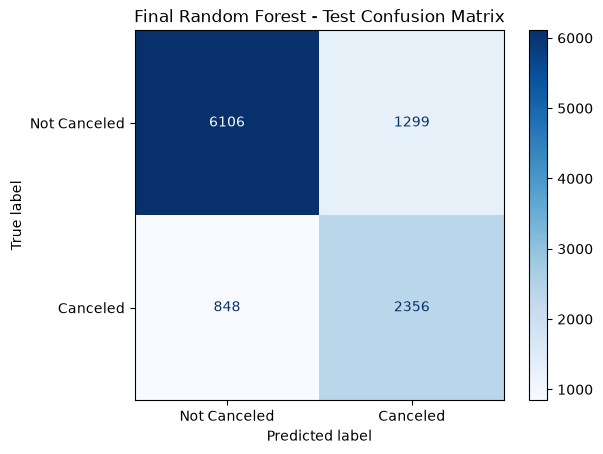

In [70]:
# Step 16.4 - Final Test Evaluation (No ADR)

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Final model: tuned Random Forest without ADR
final_model = clone(rf_no_adr)

# Remove ADR from test inputs
X_test_no_adr = X_test.drop(columns=["ADR"])

# Verify consistent feature columns
assert X_train_no_adr.columns.equals(X_test_no_adr.columns)
assert "ADR" not in X_test_no_adr.columns

# Fit ONLY on training data
final_model.fit(X_train_no_adr, y_train)

# Predict on held-out test data
y_test_pred = final_model.predict(X_test_no_adr)
y_test_prob = final_model.predict_proba(X_test_no_adr)[:, 1]

# Final metrics
final_test_results = pd.DataFrame([{
    "Model": "Tuned Random Forest - No ADR",
    "F1": f1_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "ROC_AUC": roc_auc_score(y_test, y_test_prob)
}])

display(final_test_results)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Canceled", "Canceled"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final Random Forest - Test Confusion Matrix")
plt.show()

In [71]:
# Step 17.1 - Save Final Trained Pipeline

import os
import joblib

os.makedirs("models", exist_ok=True)

model_path = "models/hotel_cancellation_rf_no_adr.joblib"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Path:", model_path)
print("File size (MB):", round(
    os.path.getsize(model_path) / (1024 ** 2), 2
))

Model saved successfully!
Path: models/hotel_cancellation_rf_no_adr.joblib
File size (MB): 66.02


In [72]:
# Step 17.2 - Load Model and Verify Predictions

import joblib
import numpy as np
import os

# Load the saved pipeline
loaded_model = joblib.load(
    "models/hotel_cancellation_rf_no_adr.joblib"
)

# Use 10 samples from the existing test inputs
# For verification only, NOT for model selection or tuning
sample_inputs = X_test_no_adr.head(10)

# Predictions from original fitted model
original_predictions = final_model.predict(sample_inputs)
original_probabilities = final_model.predict_proba(sample_inputs)

# Predictions from loaded model
loaded_predictions = loaded_model.predict(sample_inputs)
loaded_probabilities = loaded_model.predict_proba(sample_inputs)

# Verify exact prediction agreement
predictions_match = np.array_equal(
    original_predictions,
    loaded_predictions
)

# Verify probability agreement
probabilities_match = np.allclose(
    original_probabilities,
    loaded_probabilities,
    rtol=0,
    atol=1e-12
)

# Verify feature schema
features_match = (
    loaded_model.feature_names_in_.tolist()
    == X_train_no_adr.columns.tolist()
)

print("Model file exists:", os.path.exists(
    "models/hotel_cancellation_rf_no_adr.joblib"
))

print("Predictions match:", predictions_match)
print("Probabilities match:", probabilities_match)
print("Feature schema matches:", features_match)

print("\nOriginal predictions:", original_predictions)
print("Loaded predictions:  ", loaded_predictions)

assert predictions_match, "Predictions mismatch!"
assert probabilities_match, "Probabilities mismatch!"
assert features_match, "Feature schema mismatch!"

print("\nModel loading and prediction verification PASSED!")

Model file exists: True
Predictions match: True
Probabilities match: True
Feature schema matches: True

Original predictions: [0 1 1 0 0 1 0 1 1 0]
Loaded predictions:   [0 1 1 0 0 1 0 1 1 0]

Model loading and prediction verification PASSED!


In [73]:
# Step 17.3 - Reusable Prediction Function

import pandas as pd
import joblib

booking_model = joblib.load(
    "models/hotel_cancellation_rf_no_adr.joblib"
)

expected_features = booking_model.feature_names_in_.tolist()

def predict_booking_cancellation(booking_data):
    """
    Predict cancellation for one new booking.

    booking_data: dictionary containing all required
    booking-time features.
    """

    # Validate input
    if not isinstance(booking_data, dict):
        raise TypeError("booking_data must be a dictionary")

    missing_features = [
        col for col in expected_features
        if col not in booking_data
    ]

    if missing_features:
        raise ValueError(
            f"Missing features: {missing_features}"
        )

    # Use exactly the columns and order expected by the model
    booking_df = pd.DataFrame(
        [{col: booking_data[col] for col in expected_features}]
    )

    prediction = int(
        booking_model.predict(booking_df)[0]
    )

    cancellation_probability = float(
        booking_model.predict_proba(booking_df)[0, 1]
    )

    return {
        "prediction": prediction,
        "status": (
            "Likely to Cancel"
            if prediction == 1
            else "Likely Not to Cancel"
        ),
        "cancellation_probability": cancellation_probability
    }

print("Prediction function created successfully!")
print("Required features:", len(expected_features))

Prediction function created successfully!
Required features: 25


In [74]:
# Step 17.3 - Integration Smoke Test

sample_booking = X_test_no_adr.iloc[0].to_dict()

result = predict_booking_cancellation(sample_booking)

print("Prediction:", result["prediction"])
print("Status:", result["status"])
print(
    "Cancellation probability:",
    f"{result['cancellation_probability']:.2%}"
)

# Verify against the already loaded pipeline
expected_prediction = int(
    loaded_model.predict(X_test_no_adr.iloc[[0]])[0]
)

assert result["prediction"] == expected_prediction

print("Integration test PASSED!")

Prediction: 0
Status: Likely Not to Cancel
Cancellation probability: 0.00%
Integration test PASSED!
